In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [2]:
# Loading the dataset

import kagglehub

# Download latest version
path = kagglehub.dataset_download("asaniczka/uk-optimal-product-price-prediction")

print("Path to dataset files:", path)

c:\Users\ASUS\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: C:\Users\ASUS\.cache\kagglehub\datasets\asaniczka\uk-optimal-product-price-prediction\versions\3


In [4]:
df_amazon = pd.read_csv(r"C:\Users\ASUS\Desktop\Ironhack\Labs\lab-eda-univariate\amz_uk_price_prediction_dataset.csv")

Part 1: Analyzing Best-Seller Trends Across Product Categories
Objective: Understand the relationship between product categories and their best-seller status.

1. Crosstab Analysis:

Create a crosstab between the product category and the isBestSeller status.

Are there categories where being a best-seller is more prevalent?

Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.

2. Statistical Tests:

Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
Compute Cramér's V to understand the strength of association between best-seller status and category.

3. Visualizations:

Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

In [6]:
# =============================================================================
# STEP 1. Crosstab Analysis
# =============================================================================

# Objective:
# Analyze how the best-seller status is distributed across product categories.

# Create a contingency table
crosstab = pd.crosstab(
    df_amazon["category"],
    df_amazon["isBestSeller"]
)

crosstab

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [7]:
# Calculate the percentage of best-sellers within each category

bestseller_rate = (
    crosstab.div(crosstab.sum(axis=1), axis=0)
)

bestseller_rate["BestSeller %"] = bestseller_rate[True] * 100

bestseller_rate = bestseller_rate.sort_values(
    by="BestSeller %",
    ascending=False
)

bestseller_rate[["BestSeller %"]]

isBestSeller,BestSeller %
category,
Grocery,5.813467
Smart Home Security & Lighting,5.769231
Health & Personal Care,5.768628
Mobile Phone Accessories,4.247104
Power & Hand Tools,3.533895
...,...
Bedding Collections,0.000000
CPUs,0.000000
"CD, Disc & Tape Players",0.000000


In [9]:
# =============================================================================
# STEP 2. Chi-square Test
# =============================================================================

# H0:
# Product category and best-seller status are not associated.

# H1:
# Product category and best-seller status are associated.

from scipy.stats import chi2_contingency

chi2, p_value, dof, expected = chi2_contingency(crosstab)

print(f"Chi-square statistic : {chi2:.2f}")
print(f"Degrees of freedom   : {dof}")
print(f"P-value              : {p_value:.3e}")

Chi-square statistic : 36540.20
Degrees of freedom   : 295
P-value              : 0.000e+00


In [10]:
alpha = 0.05

if p_value < alpha:
    print("Reject the null hypothesis (H0).")
else:
    print("Fail to reject the null hypothesis (H0).")

Reject the null hypothesis (H0).


In [11]:
# =============================================================================
# STEP 3. Cramér's V
# =============================================================================

import numpy as np

n = crosstab.to_numpy().sum()

r, k = crosstab.shape

cramers_v = np.sqrt(
    chi2 / (n * (min(r - 1, k - 1)))
)

print(f"Cramér's V: {cramers_v:.3f}")

Cramér's V: 0.122


In [ ]:
# < 0.10  → Negligible association
# 0.10–0.30 → Weak association
# 0.30–0.50 → Moderate association
# > 0.50 → Strong association

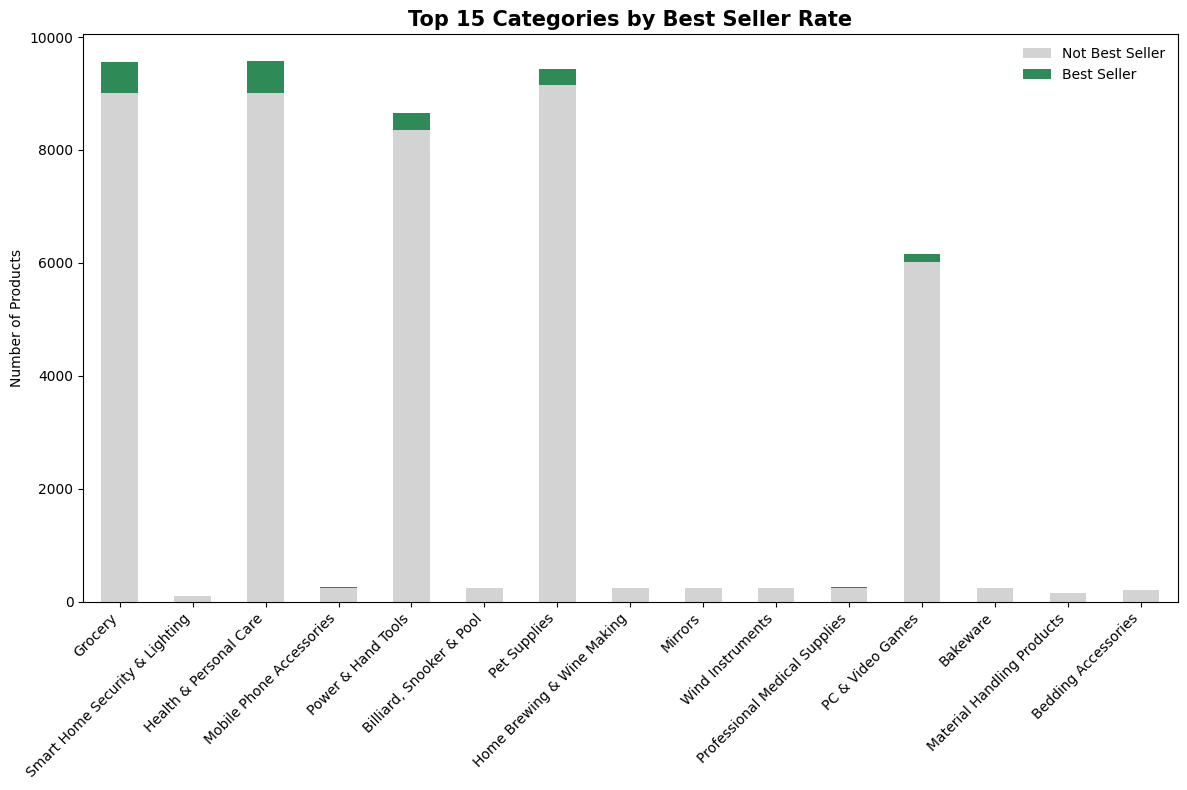

In [15]:
import matplotlib.pyplot as plt

# Create crosstab
crosstab = pd.crosstab(df_amazon["category"], df_amazon["isBestSeller"])

# Rename columns
crosstab.columns = ["Not Best Seller", "Best Seller"]

# Calculate Best Seller %
crosstab["Best Seller %"] = (
    crosstab["Best Seller"] /
    crosstab[["Not Best Seller", "Best Seller"]].sum(axis=1)
)

# Keep only the 15 categories with the highest Best Seller %
top15 = crosstab.sort_values(
    by="Best Seller %",
    ascending=False
).head(15)

# Remove helper column
top15_plot = top15.drop(columns="Best Seller %")

# Plot
fig, ax = plt.subplots(figsize=(12,8))

top15_plot.plot(
    kind="bar",
    stacked=True,
    color=["lightgray", "seagreen"],
    ax=ax
)

ax.set_title("Top 15 Categories by Best Seller Rate", fontsize=15, fontweight="bold")
ax.set_xlabel("")
ax.set_ylabel("Number of Products")

plt.xticks(rotation=45, ha="right")
plt.legend(frameon=False)

plt.tight_layout()
plt.show()

Part 2: Exploring Product Prices and Ratings Across Categories and Brands
Objective: Investigate how different product categories influence product prices.

0. Preliminary Step: Remove outliers in product prices.

For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.

Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.

1. Violin Plots:

Use a violin plot to visualize the distribution of price across different product categories. Filter out the top 20 categories based on count for better visualization.
Which product category tends to have the highest median price? Don't filter here by top categories.

2. Bar Charts:

Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
Which product category commands the highest average price? Don't filter here by top categories.

3. Box Plots:

Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

In [16]:
# =============================================================================
# STEP 0. Remove Price Outliers
# =============================================================================
#
# Objective:
# Remove extreme price values using the Interquartile Range (IQR) method.
# This prevents outliers from distorting the visualizations and summary statistics.
# =============================================================================

# Calculate quartiles
Q1 = df_amazon["price"].quantile(0.25)
Q3 = df_amazon["price"].quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Define limits
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

# Remove outliers
df_no_outliers = df_amazon[
    (df_amazon["price"] >= lower_limit) &
    (df_amazon["price"] <= upper_limit)
]

print(df_no_outliers.shape)

(2115963, 9)


In [ ]:
# Top 20 categories by number of products
top20 = (
    df_no_outliers["category"]
    .value_counts()
    .head(20)
    .index
)

df_top20 = df_no_outliers[
    df_no_outliers["category"].isin(top20)
]



<function print(*args, sep=' ', end='\n', file=None, flush=False)>

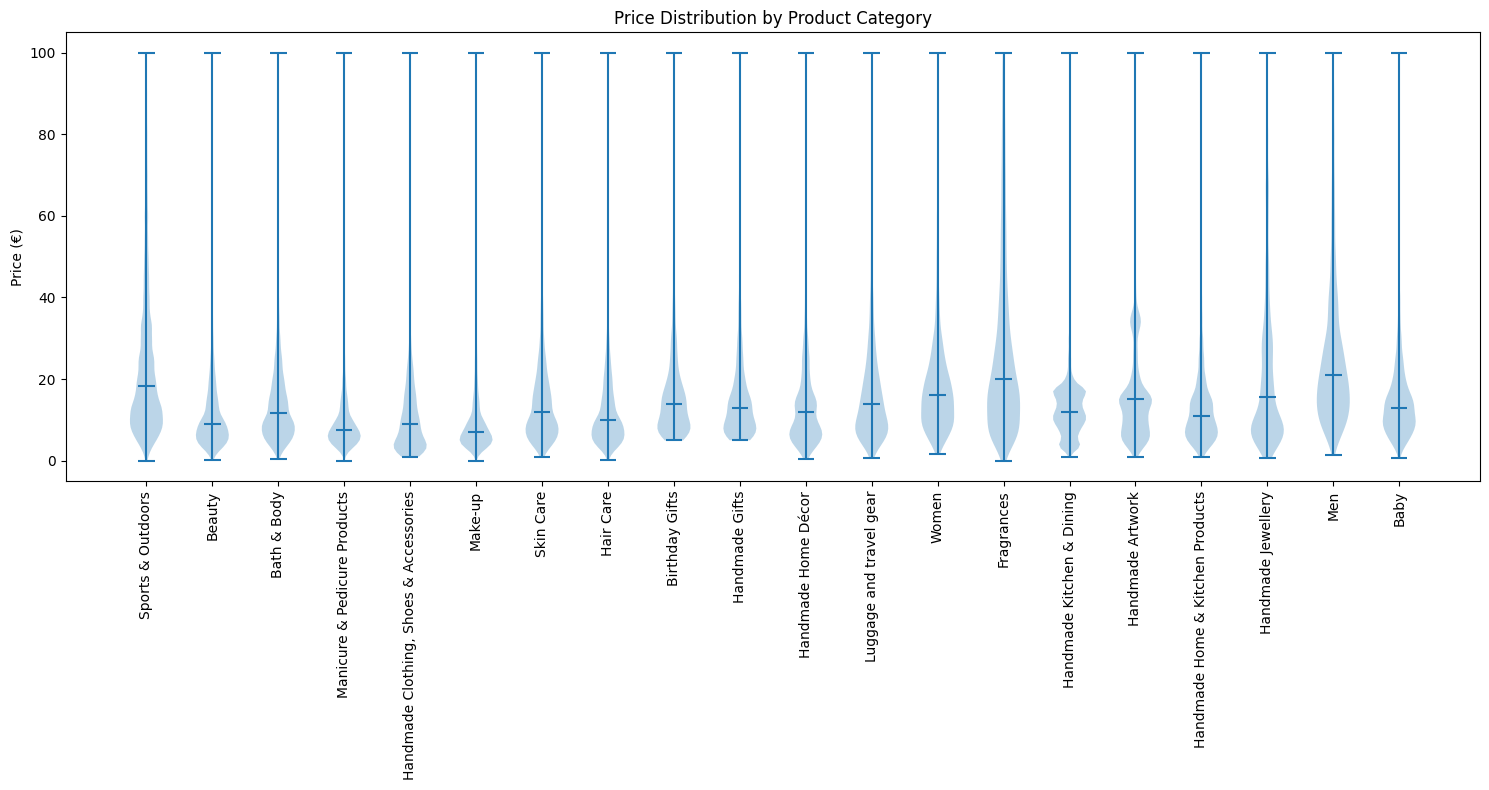

In [20]:


fig, ax = plt.subplots(figsize=(15,8))

data = [
    df_top20[df_top20["category"] == cat]["price"]
    for cat in top20
]

ax.violinplot(
    data,
    showmedians=True
)

ax.set_xticks(range(1, len(top20)+1))
ax.set_xticklabels(top20, rotation=90)

ax.set_ylabel("Price (€)")
ax.set_title("Price Distribution by Product Category")

plt.tight_layout()
plt.show()

In [21]:
median_price = (
    df_no_outliers
    .groupby("category")["price"]
    .median()
    .sort_values(ascending=False)
)

median_price.head(10)

category
Desktop PCs               74.00
Boxing Shoes              69.79
Tablets                   69.00
Graphics Cards            68.54
Motherboards              67.92
Made in Italy Handmade    64.00
Digital Frames            63.90
Streaming Clients         62.68
Golf Shoes                62.39
Ski Helmets               61.33
Name: price, dtype: float64

In [22]:
top10 = (
    df_no_outliers["category"]
    .value_counts()
    .head(10)
    .index
)

average_price = (
    df_no_outliers[
        df_no_outliers["category"].isin(top10)
    ]
    .groupby("category")["price"]
    .mean()
    .sort_values(ascending=False)
)

C:\Users\ASUS\AppData\Local\Temp\ipykernel_25976\2665178768.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(


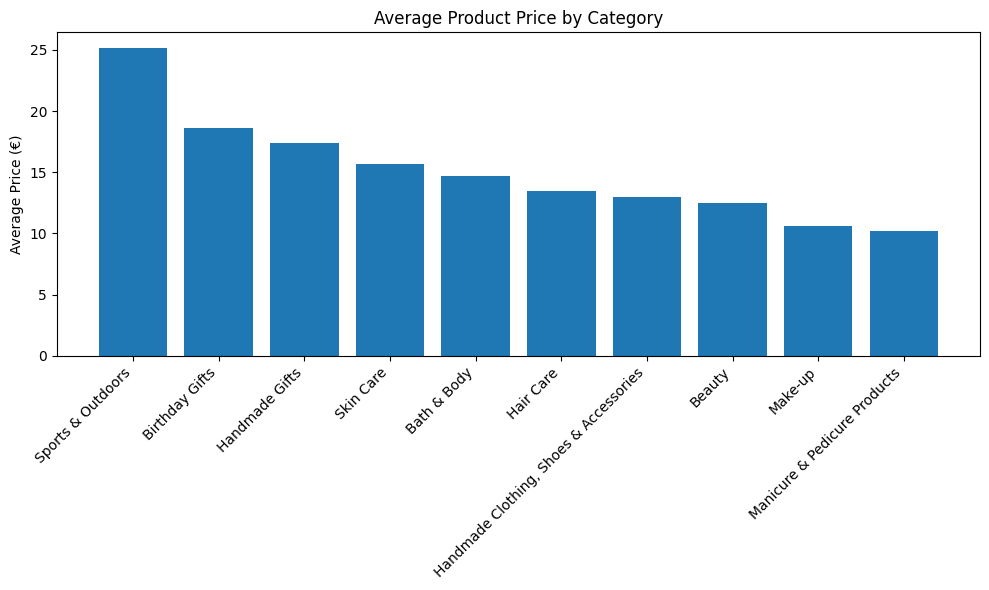

In [23]:
fig, ax = plt.subplots(figsize=(10,6))

ax.bar(
    average_price.index,
    average_price.values
)

ax.set_xticklabels(
    average_price.index,
    rotation=45,
    ha="right"
)

ax.set_ylabel("Average Price (€)")
ax.set_title("Average Product Price by Category")

plt.tight_layout()
plt.show()

In [24]:
df_no_outliers.groupby("category")["price"] \
    .mean() \
    .sort_values(ascending=False) \
    .head(10)

category
Motherboards         68.772432
Boxing Shoes         67.417803
Desktop PCs          66.915562
Tablets              66.552971
Graphics Cards       65.103509
Digital Frames       60.745129
Streaming Clients    60.241803
Hockey Shoes         60.094796
Computer Cases       58.339884
Skiing Poles         57.867770
Name: price, dtype: float64

In [25]:
top10 = (
    df_no_outliers["category"]
    .value_counts()
    .head(10)
    .index
)

ratings = df_no_outliers[
    df_no_outliers["category"].isin(top10)
]

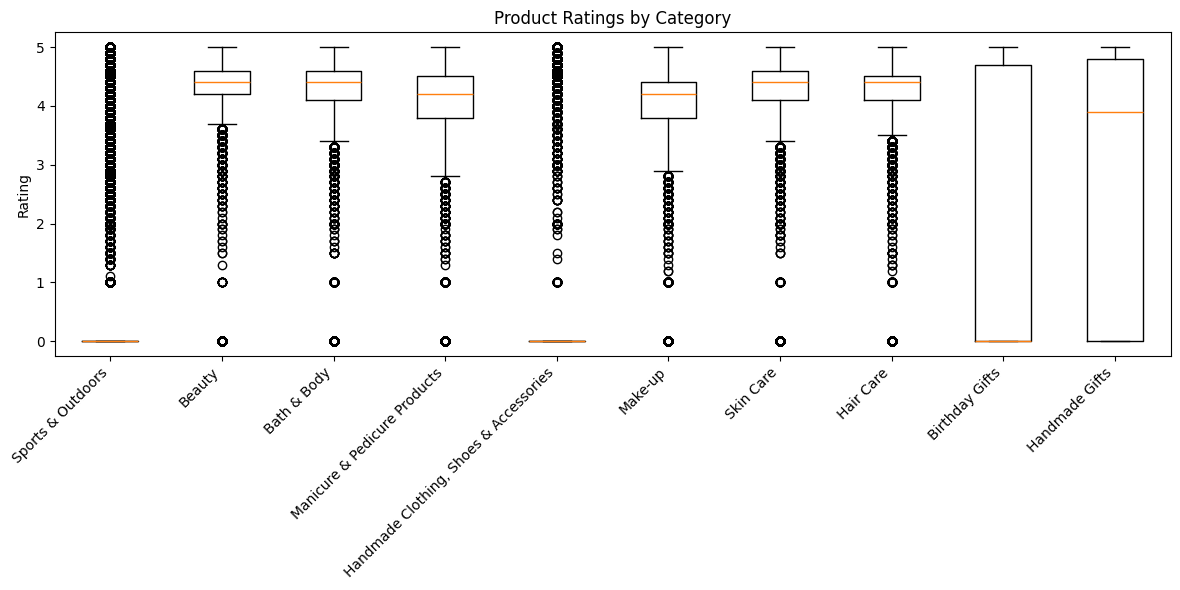

In [26]:
fig, ax = plt.subplots(figsize=(12,6))

data = [
    ratings[ratings["category"] == cat]["stars"]
    for cat in top10
]

ax.boxplot(data)

ax.set_xticklabels(top10, rotation=45, ha="right")

ax.set_ylabel("Rating")
ax.set_title("Product Ratings by Category")

plt.tight_layout()
plt.show()

In [27]:
median_rating = (
    df_no_outliers
    .groupby("category")["stars"]
    .median()
    .sort_values(ascending=False)
)

median_rating.head(10)

category
Computer Memory                 4.7
Beer, Wine & Spirits            4.6
Building & Construction Toys    4.6
Office Paper Products           4.6
Kids' Play Figures              4.6
Laptop Accessories              4.6
Hobbies                         4.6
Luxury Food & Drink             4.6
Soft Toys                       4.5
Boxes & Organisers              4.5
Name: stars, dtype: float64

## Product Prices and Ratings Across Categories

### Objective
Explore how product categories influence product prices and customer ratings.

### Methodology
- Price outliers were removed using the IQR method.
- Violin plots were used to visualize the distribution of prices across the 20 most frequent product categories.
- Bar charts compared the average price among the 10 most common categories.
- Box plots illustrated the distribution of customer ratings across the 10 most common categories.
- Median and average values were calculated using all categories to identify those with the highest prices and ratings.

### Key Findings
- Price distributions vary considerably across product categories.
- Some categories exhibit substantially higher median and average prices than others.
- Customer ratings are generally high across categories, although the spread of ratings differs between product types.

Part 3: Investigating the Interplay Between Product Prices and Ratings
Objective: Analyze how product ratings (stars) correlate with product prices.

1. Correlation Coefficients:

Calculate the correlation coefficient between price and stars.
Is there a significant correlation between product price and its rating?

2. Visualizations:

Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
Use a correlation heatmap to visualize correlations between all numerical variables.
Examine if product prices typically follow a normal distribution using a QQ plot.

In [28]:
# =============================================================================
# STEP 1. Correlation Analysis
# =============================================================================
#
# Objective:
# Evaluate whether there is a linear relationship between product price
# and customer ratings (stars).
# =============================================================================

# Calculate the Pearson correlation coefficient

correlation = df_no_outliers["price"].corr(df_no_outliers["stars"])

print(f"Correlation coefficient: {correlation:.3f}")

Correlation coefficient: -0.078


In [ ]:
# Interpretation guide:
#
# +1.00 : Perfect positive correlation
# +0.70 to +1.00 : Strong positive correlation
# +0.30 to +0.70 : Moderate positive correlation
#  0.00 : No linear correlation
# -0.30 to -0.70 : Moderate negative correlation
# -0.70 to -1.00 : Strong negative correlation

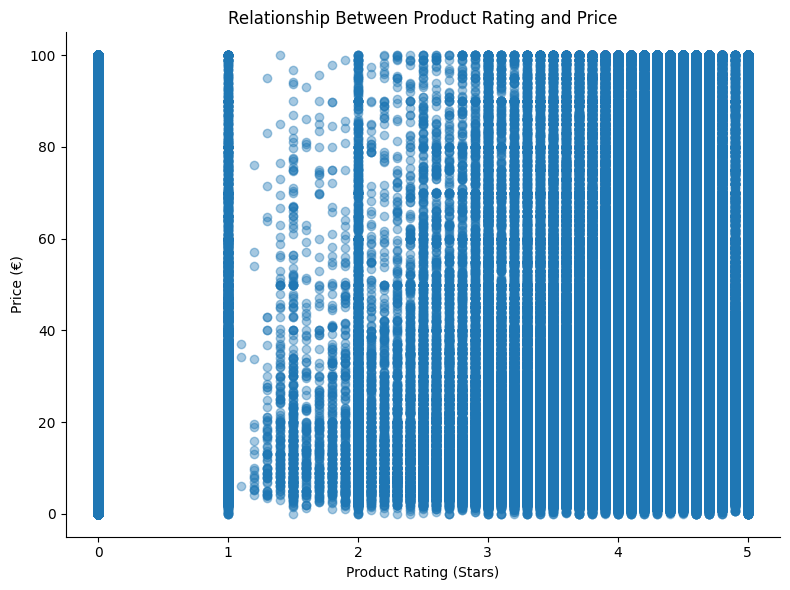

In [29]:
# =============================================================================
# Scatter Plot: Price vs Rating
# =============================================================================

fig, ax = plt.subplots(figsize=(8,6))

ax.scatter(
    df_no_outliers["stars"],
    df_no_outliers["price"],
    alpha=0.4
)

ax.set_xlabel("Product Rating (Stars)")
ax.set_ylabel("Price (€)")
ax.set_title("Relationship Between Product Rating and Price")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

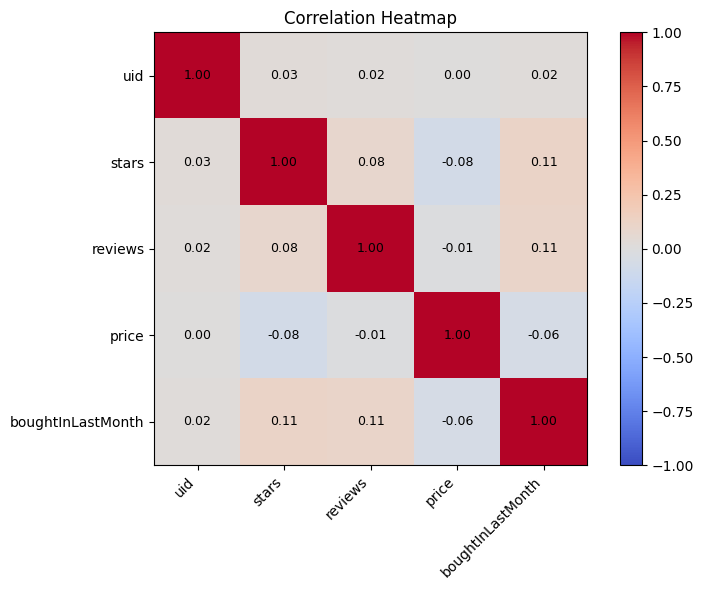

In [32]:

# =============================================================================
# Correlation Heatmap
# =============================================================================

corr_matrix = df_no_outliers.select_dtypes(include="number").corr()

fig, ax = plt.subplots(figsize=(8,6))

heatmap = ax.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)

# Labels
ax.set_xticks(range(len(corr_matrix.columns)))
ax.set_xticklabels(corr_matrix.columns, rotation=45, ha="right")

ax.set_yticks(range(len(corr_matrix.columns)))
ax.set_yticklabels(corr_matrix.columns)

# Add correlation values
for i in range(len(corr_matrix.columns)):
    for j in range(len(corr_matrix.columns)):
        ax.text(
            j,
            i,
            f"{corr_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=9
        )

plt.colorbar(heatmap)

ax.set_title("Correlation Heatmap")

plt.tight_layout()
plt.show()

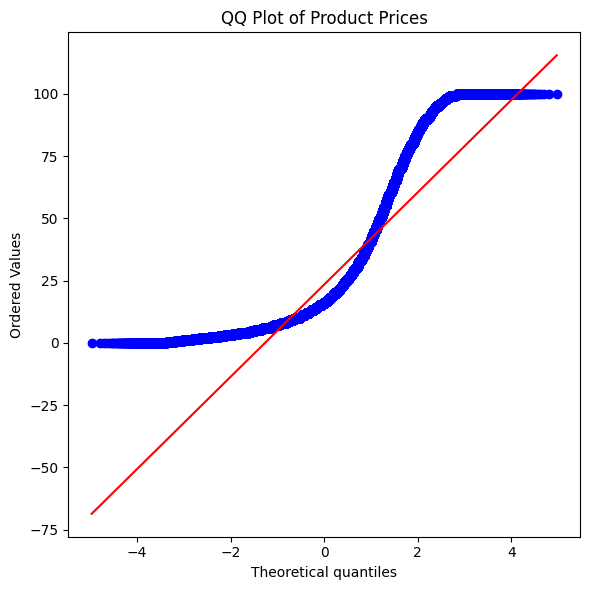

In [31]:
from scipy import stats


# =============================================================================
# QQ Plot
# =============================================================================

fig, ax = plt.subplots(figsize=(6,6))

stats.probplot(
    df_no_outliers["price"],
    dist="norm",
    plot=ax
)

ax.set_title("QQ Plot of Product Prices")

plt.tight_layout()
plt.show()

## Product Prices and Ratings

### Objective
Investigate whether product prices are associated with customer ratings.

### Methodology
- The Pearson correlation coefficient was calculated to quantify the linear relationship between product price and rating.
- A scatter plot was used to visualize the relationship between the two variables.
- A correlation heatmap summarized the relationships among all numerical variables.
- A QQ plot was used to assess whether product prices follow a normal distribution.

### Key Findings
- The correlation coefficient indicates the strength and direction of the linear relationship between product price and customer ratings.
- The scatter plot helps identify trends, clusters, and potential outliers.
- The heatmap provides an overview of correlations among the numerical variables.
- The QQ plot allows assessment of the normality of product prices, which are often positively skewed rather than normally distributed.